# 01 — Source Profiling (Workshop #1)
**Team 6 — Volcanic Activity Monitoring** · Data Analysis Programming 2026-II · Universidad Distrital

**Scope: United States volcanoes** (decision of 2026-11-09). This notebook profiles the **real, unmodified** responses stored in `workshop_1/samples/` by `scripts/fetch_samples.py`:

| # | Source | Role | Format |
|---|---|---|---|
| H1 | Smithsonian GVP — Holocene volcanoes (US, `CQL_FILTER`) + eruptions of those volcanoes (WFS) | historical | GeoJSON |
| H2 | USGS FDSN event service, radial queries (30 km) around US volcanoes | historical | CSV |
| I1 | USGS HANS public API — alert level + aviation colour code per volcano | incremental | JSON |
| I2 | USGS real-time feed `all_week` | incremental | GeoJSON |
| O | Smithsonian / USGS Weekly Volcanic Activity Report (optional, context) | optional | RSS XML |

Sections: 1) inventory · 2) per-source profiles (nulls, ranges, duplicates, time zones, coordinates, units) · 3) update behaviour between two polls · 4) data-quality problems · 5) cross-source overlap (candidate same-event pairs) · 6) volume estimate.

In [1]:
import json, os, re, sys, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from volcano_pipeline.sources import weekly_report, gvp
from volcano_pipeline.normalization.geo import haversine_km, valid_coordinates

SAMPLES = Path(os.getenv("SAMPLES_DIR", ROOT / "workshop_1" / "samples"))
RAW = Path(os.getenv("RAW_DATA_DIR", ROOT / "data" / "raw"))
RADIUS_KM = 30
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
print("samples dir:", SAMPLES)

samples dir: C:\Users\jhona\OneDrive\Escritorio\Proyecto final analisis datos\workshop_1\samples


## 1. Inventory of the evidence files

In [2]:
rows = []
for f in sorted(SAMPLES.glob("*")):
    if f.name.endswith(".meta.json") or f.is_dir():
        continue
    meta_f = f.with_suffix(f.suffix + ".meta.json")
    meta = json.loads(meta_f.read_text()) if meta_f.exists() else {}
    rows.append({"file": f.name, "source_id": meta.get("source_id", f.name.split("_2")[0]),
                 "retrieved_utc": meta.get("retrieved_utc"), "KB": round(f.stat().st_size/1024, 1),
                 "sha256": (meta.get("sha256") or "")[:12],
                 "etag": meta.get("headers", {}).get("ETag") or meta.get("headers", {}).get("Etag"),
                 "last_modified": meta.get("headers", {}).get("Last-Modified")})
inventory = pd.DataFrame(rows)
inventory

,file,source_id,retrieved_utc,KB,sha256,etag,last_modified
0,gdacs_vo_20261110_024938.json,gdacs_vo,2026-11-10T02:49:38.221459+00:00,9.0,c67733e60fde,NaN,NaN
1,gvp_eruptions_us_20261110_024941.geojson,gvp_eruptions,2026-11-10T02:49:41.700720+00:00,1010.7,0cf4ef0effaf,NaN,NaN
2,gvp_volcanoes_20261110_024940.geojson,gvp_volcanoes,2026-11-10T02:49:40.115589+00:00,331.8,9d1103c1819b,NaN,NaN
3,gvp_weekly_cap_20261110_024935.xml,gvp_weekly_cap,2026-11-10T02:49:35.978850+00:00,42.6,d7e75df01aa9,"""804464efd85cdd1:0""","Thu, 15 Oct 2026 19:11:09 GMT"
4,gvp_weekly_rss_20261110_024935.xml,gvp_weekly_rss,2026-11-10T02:49:35.773988+00:00,35.8,b51a2500dcb9,"""804464efd85cdd1:0""","Thu, 15 Oct 2026 19:11:09 GMT"
5,README.md,README.md,NaN,0.3,,NaN,NaN
6,usgs_fdsn_counts_20261110_025257.json,usgs_fdsn_counts,NaN,3.0,,NaN,NaN
7,usgs_fdsn_v311120_20261110_024946.csv,usgs_fdsn,2026-11-10T02:49:46.363320+00:00,17.6,e5030eb8238d,NaN,"Tue, 10 Nov 2026 02:49:49 GMT"
8,usgs_fdsn_v311360_20261110_024947.csv,usgs_fdsn,2026-11-10T02:49:47.653361+00:00,16.7,1d864ef6d0c7,NaN,"Tue, 10 Nov 2026 02:49:50 GMT"
9,usgs_fdsn_v313040_20261110_024949.csv,usgs_fdsn,2026-11-10T02:49:49.184840+00:00,35.2,f4a78670076e,NaN,"Tue, 10 Nov 2026 02:49:52 GMT"


In [3]:
def files(prefix, ext=None):
    fs = [f for f in sorted(SAMPLES.glob(prefix + "*")) if not f.name.endswith(".meta.json")]
    return [f for f in fs if ext is None or f.suffix == ext]

def latest(prefix):
    fs = files(prefix)
    if not fs:
        raise FileNotFoundError(f"No sample for {prefix}: run python scripts/fetch_samples.py")
    return fs[-1]

def profile(df, name):
    """Generic profile: dtype, null %, distinct, min/max per column."""
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null_%": (df.isna().mean() * 100).round(2),
        "distinct": df.nunique(dropna=True),
    })
    num = df.select_dtypes("number")
    out["min"] = num.min(); out["max"] = num.max()
    print(f"{name}: {len(df):,} rows x {df.shape[1]} columns")
    return out

def col(df, *cands):
    for c in cands:
        if c in df.columns:
            return c
    raise KeyError(f"none of {cands} in columns")

## 2. Source profiles
### 2.1 H1 — GVP Holocene volcanoes (static reference entity)

In [4]:
vol_file = latest("gvp_volcanoes")
volcanoes = pd.DataFrame(gvp.parse_features(vol_file.read_bytes()))
print("file:", vol_file.name)
print("columns:", list(volcanoes.columns))
profile(volcanoes, "GVP volcanoes")

file: gvp_volcanoes_20261110_024940.geojson
columns: ['Volcano_Number', 'Volcano_Name', 'Volcanic_Landform', 'Primary_Volcano_Type', 'Last_Eruption_Year', 'Country', 'Region', 'Subregion', 'Geological_Summary', 'Latitude', 'Longitude', 'Elevation', 'Tectonic_Setting', 'Geologic_Epoch', 'Evidence_Category', 'Primary_Photo_Link', 'Primary_Photo_Caption', 'Primary_Photo_Credit', 'Major_Rock_Type', '_lon', '_lat', '_feature_id']
GVP volcanoes: 165 rows x 22 columns


,dtype,null_%,distinct,min,max
Volcano_Number,int64,0.00,165,244000.000,332060.000
Volcano_Name,str,0.00,165,NaN,NaN
Volcanic_Landform,str,0.00,7,NaN,NaN
Primary_Volcano_Type,str,0.00,17,NaN,NaN
Last_Eruption_Year,float64,26.67,96,-9450.000,2026.000
Country,str,0.00,1,NaN,NaN
Region,str,0.00,4,NaN,NaN
Subregion,str,0.00,17,NaN,NaN
Geological_Summary,str,0.00,165,NaN,NaN
Latitude,float64,0.00,164,-14.601,65.517


In [5]:
VN, VNAME = col(volcanoes, "Volcano_Number"), col(volcanoes, "Volcano_Name")
VLAT, VLON = col(volcanoes, "Latitude", "_lat"), col(volcanoes, "Longitude", "_lon")
volcanoes[VN] = pd.to_numeric(volcanoes[VN], errors="coerce").astype("Int64")
print("duplicated volcano numbers:", volcanoes[VN].duplicated().sum())
print("invalid coordinates:", (~volcanoes.apply(lambda r: valid_coordinates(r[VLAT], r[VLON]), axis=1)).sum())
lec = col(volcanoes, "Last_Eruption_Year")
ley = pd.to_numeric(volcanoes[lec], errors="coerce")
print(f"Last_Eruption_Year: non-numeric/unknown = {ley.isna().sum()}, BCE (<0) = {(ley < 0).sum()}, since 1900 = {(ley >= 1900).sum()}")
volcanoes[[VN, VNAME, col(volcanoes, 'Country'), VLAT, VLON, lec]].head()

duplicated volcano numbers: 0
invalid coordinates: 0
Last_Eruption_Year: non-numeric/unknown = 44, BCE (<0) = 31, since 1900 = 52


,Volcano_Number,Volcano_Name,Country,Latitude,Longitude,Last_Eruption_Year
0,244000,Vailuluu,United States,-14.2150,-169.0580,2003.0
1,244001,Tau,United States,-14.2300,-169.4540,NaN
2,244010,Ofu-Olosega,United States,-14.1750,-169.6180,1866.0
3,244020,Tutuila,United States,-14.2903,-170.7019,440.0
4,284133,Fukujin,United States,21.9300,143.4700,1974.0


### 2.2 H1 — GVP Holocene eruptions

In [6]:
er_file = latest("gvp_eruptions")
eruptions = pd.DataFrame(gvp.parse_features(er_file.read_bytes()))
print("file:", er_file.name); print("columns:", list(eruptions.columns))
profile(eruptions, "GVP eruptions")

file: gvp_eruptions_us_20261110_024941.geojson
columns: ['Volcano_Number', 'Volcano_Name', 'Eruption_Number', 'Activity_Type', 'ExplosivityIndexMax', 'ExplosivityIndexModifier', 'ActivityArea', 'ActivityUnit', 'StartEvidenceMethod', 'StartDateYearModifier', 'StartDateYear', 'StartDateYearUncertainty', 'StartDateDayModifier', 'StartDateMonth', 'StartDateDay', 'StartDateDayUncertainty', 'EndDateYearModifier', 'EndDateYear', 'EndDateYearUncertainty', 'EndDateDayModifier', 'EndDateMonth', 'EndDateDay', 'EndDateDayUncertainty', '_lon', '_lat', '_feature_id']
GVP eruptions: 1,281 rows x 26 columns


,dtype,null_%,distinct,min,max
Volcano_Number,int64,0.00,123,244000.0000,332060.000
Volcano_Name,str,0.00,123,NaN,NaN
Eruption_Number,int64,0.00,1281,10057.0000,22656.000
Activity_Type,str,0.00,2,NaN,NaN
ExplosivityIndexMax,float64,37.47,8,0.0000,7.000
ExplosivityIndexModifier,str,90.32,5,NaN,NaN
ActivityArea,str,51.83,361,NaN,NaN
ActivityUnit,str,91.33,108,NaN,NaN
StartEvidenceMethod,str,13.66,20,NaN,NaN
StartDateYearModifier,str,82.12,3,NaN,NaN


duplicated Eruption_Number: 0
VEI missing: 37.5%  range: 0.0-7.0
start-date precision:
 day      657
year     619
month      5
Name: count, dtype: int64
eruptions whose volcano is not in the Holocene volcano list: 0


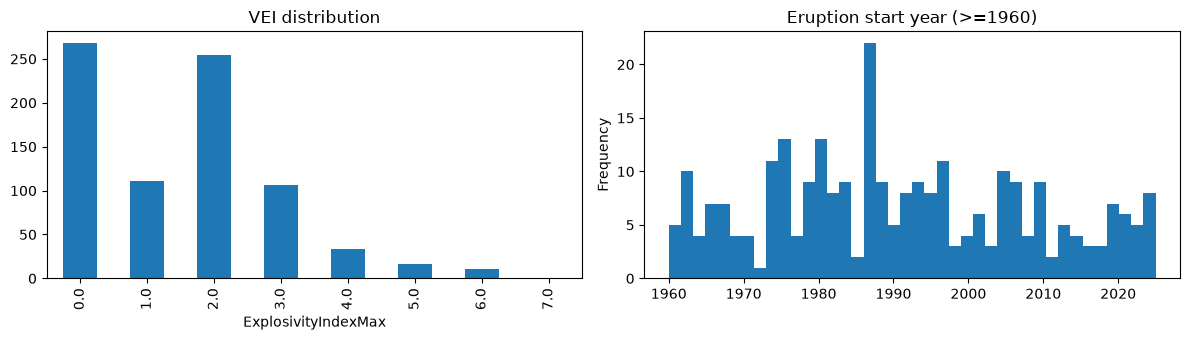

In [7]:
EN = col(eruptions, "Eruption_Number"); EVN = col(eruptions, "Volcano_Number")
VEI = col(eruptions, "ExplosivityIndexMax", "VEI")
SY, SM, SD = col(eruptions, "StartDateYear"), col(eruptions, "StartDateMonth"), col(eruptions, "StartDateDay")
for c in (SY, SM, SD, VEI, EVN):
    eruptions[c] = pd.to_numeric(eruptions[c], errors="coerce")
print("duplicated Eruption_Number:", eruptions[EN].duplicated().sum())
print(f"VEI missing: {eruptions[VEI].isna().mean():.1%}  range: {eruptions[VEI].min()}-{eruptions[VEI].max()}")
precision = np.select([eruptions[SD].fillna(0) > 0, eruptions[SM].fillna(0) > 0], ["day", "month"], "year")
print("start-date precision:\n", pd.Series(precision).value_counts())
orphans = ~eruptions[EVN].isin(volcanoes[VN].astype(float))
print("eruptions whose volcano is not in the Holocene volcano list:", orphans.sum())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
eruptions[VEI].value_counts().sort_index().plot.bar(ax=ax[0], title="VEI distribution")
eruptions.loc[eruptions[SY] >= 1960, SY].plot.hist(bins=40, ax=ax[1], title="Eruption start year (>=1960)")
plt.tight_layout()

### 2.3 H2 — USGS FDSN earthquakes around volcanoes (CSV)

In [8]:
fdsn_files = files("usgs_fdsn_", ".csv")
parts = []
for f in fdsn_files:
    d = pd.read_csv(f)
    m = re.search(r"_v(\d{6})_", f.name)
    d["query_vnum"] = int(m.group(1)) if m else None
    parts.append(d)
fdsn = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
print(len(fdsn_files), "files; columns:", list(fdsn.columns))
profile(fdsn, "USGS FDSN")

7 files; columns: ['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource', 'query_vnum']
USGS FDSN: 3,432 rows x 23 columns


,dtype,null_%,distinct,min,max
time,str,0.00,2997,NaN,NaN
latitude,float64,0.00,2138,19.160334,61.555000
longitude,float64,0.00,2295,-176.467833,-121.653833
depth,float64,0.00,2145,-3.380000,230.200000
mag,float64,0.00,222,1.000000,5.960000
magType,str,0.00,6,NaN,NaN
nst,float64,0.09,83,4.000000,163.000000
gap,float64,0.09,279,22.000000,330.000000
dmin,float64,0.12,2393,0.000000,0.700000
rms,float64,0.00,99,0.030000,4.192687


time zone check (all times end with Z): True
coverage: 2025-11-10 01:20:17.060000+00:00 -> 2026-11-09 18:54:11.690000+00:00
rows per query volcano:
 query_vnum
332010    2185
332020     741
313040     196
311120      91
311360      81
321050      71
321030      67
Name: count, dtype: int64

event types: {'earthquake': 3424, 'explosion': 7, 'other event': 1}
magnitude types: {'ml': 2431, 'md': 990, 'mb': 8, 'mww': 1, 'mh': 1, 'mw': 1}
status: {'reviewed': 2392, 'automatic': 1040}
negative depths (above sea level): 219
ids repeated across volcano queries (one quake near 2+ volcanoes): 435


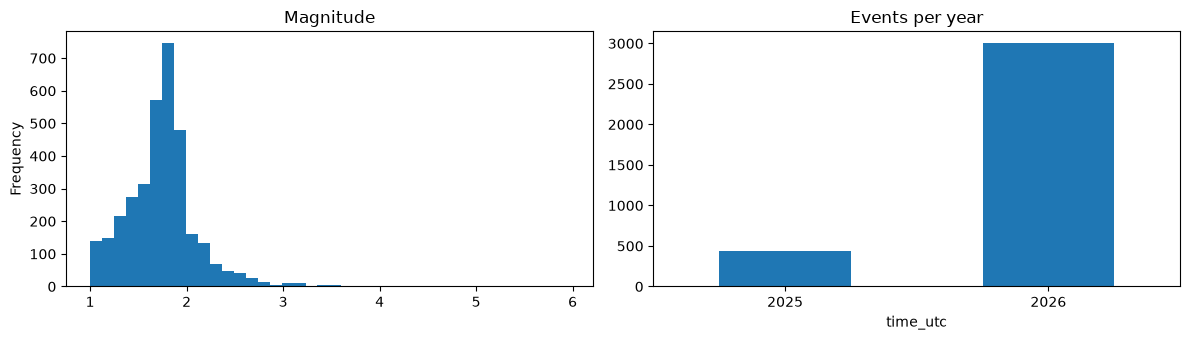

In [9]:
print("time zone check (all times end with Z):", fdsn["time"].astype(str).str.endswith("Z").all())
fdsn["time_utc"] = pd.to_datetime(fdsn["time"], utc=True, format="ISO8601")
fdsn["updated_utc"] = pd.to_datetime(fdsn["updated"], utc=True, format="ISO8601")
print("coverage:", fdsn["time_utc"].min(), "->", fdsn["time_utc"].max())
print("rows per query volcano:\n", fdsn["query_vnum"].value_counts())
print("\nevent types:", fdsn["type"].value_counts().to_dict())
print("magnitude types:", fdsn["magType"].value_counts().to_dict())
print("status:", fdsn["status"].value_counts().to_dict())
print("negative depths (above sea level):", (fdsn["depth"] < 0).sum())
dup_ids = fdsn["id"].duplicated(keep=False)
print("ids repeated across volcano queries (one quake near 2+ volcanoes):", fdsn.loc[dup_ids, "id"].nunique())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
fdsn["mag"].plot.hist(bins=40, ax=ax[0], title="Magnitude")
fdsn.set_index("time_utc").resample("YE")["id"].count().plot.bar(ax=ax[1], title="Events per year")
plt.tight_layout()

### 2.4 I1 — USGS HANS: current alert level and aviation colour code
`getMonitoredVolcanoes` returns the latest notice for each monitored US volcano; `getUSVolcanoes` is the reference list (vnum + coordinates) used to locate notices, because notices carry no coordinates.

In [10]:
hans_files = files("usgs_hans_monitored", ".json")
hans = pd.DataFrame(json.loads(hans_files[-1].read_bytes()))
hans_us = pd.DataFrame(json.loads(latest("usgs_hans_us_volcanoes").read_bytes()))
print("file:", hans_files[-1].name, "| columns:", list(hans.columns))
display(profile(hans, "HANS monitored volcanoes"))
hans["sent_dt"] = pd.to_datetime(hans["sent_unixtime"], unit="s", utc=True)
print("sent_utc has no time-zone suffix; equals sent_unixtime in UTC:",
      (pd.to_datetime(hans["sent_utc"], utc=True) == hans["sent_dt"]).all())
print("alert level x colour code:\n", hans.groupby(["alert_level", "color_code"]).size())
print("notice age (days) — min/median/max:",
      (pd.Timestamp.now(tz="UTC") - hans["sent_dt"]).dt.days.describe()[["min", "50%", "max"]].to_dict())
print("observatories:", hans["obs_abbr"].value_counts().to_dict())
print("duplicated vnum:", hans["vnum"].duplicated().sum(),
      " notices shared by several volcanoes:", hans["notice_identifier"].duplicated(keep=False).sum())

file: usgs_hans_monitored_20261110_024934.json | columns: ['volcano_name', 'vnum', 'sent_utc', 'sent_unixtime', 'alert_level', 'color_code', 'volcano_cd', 'obs_fullname', 'obs_abbr', 'notice_type_cd', 'notice_identifier', 'notice_url', 'notice_data']
HANS monitored volcanoes: 69 rows x 13 columns


,dtype,null_%,distinct,min,max
volcano_name,str,0.00,69,NaN,NaN
vnum,str,2.90,67,NaN,NaN
sent_utc,str,18.84,43,NaN,NaN
sent_unixtime,int64,0.00,44,0.0,1.794259e+09
alert_level,str,0.00,3,NaN,NaN
color_code,str,0.00,3,NaN,NaN
volcano_cd,str,0.00,69,NaN,NaN
obs_fullname,str,0.00,6,NaN,NaN
obs_abbr,str,0.00,6,NaN,NaN
notice_type_cd,str,0.00,6,NaN,NaN


sent_utc has no time-zone suffix; equals sent_unixtime in UTC: False
alert level x colour code:
 alert_level  color_code
ADVISORY     YELLOW         2
NORMAL       GREEN         66
WATCH        ORANGE         1
dtype: int64
notice age (days) — min/median/max: {'min': 0.0, '50%': 1034.0, 'max': 20767.0}
observatories: {'avo': 37, 'calvo': 11, 'cvo': 11, 'hvo': 8, 'nmi': 1, 'yvo': 1}
duplicated vnum: 1  notices shared by several volcanoes: 34


In [11]:
# vnum is the join key with GVP: check it
gvp_vn = set(volcanoes[VN].astype(int).astype(str))
for name, d in (("monitored", hans), ("us_volcanoes", hans_us)):
    bad = d[~d["vnum"].astype(str).str.fullmatch(r"\d{6}") | d["vnum"].astype(str).isin(["0", "999999"])]
    not_gvp = d[~d["vnum"].astype(str).isin(gvp_vn) & ~d.index.isin(bad.index)]
    print(f"{name}: {len(d)} rows | placeholder/invalid vnum: {len(bad)} | valid vnum not in GVP Holocene US list: {len(not_gvp)}")
    display(pd.concat([bad, not_gvp])[["vnum", "volcano_name"] + (["region"] if "region" in d else [])].head(20))
print("GVP US volcanoes without a HANS entry:", len(gvp_vn - set(hans_us["vnum"].astype(str))))
hans[hans["alert_level"] != "NORMAL"][["volcano_name", "vnum", "alert_level", "color_code", "sent_utc", "notice_identifier"]]

monitored: 69 rows | placeholder/invalid vnum: 2 | valid vnum not in GVP Holocene US list: 5


,vnum,volcano_name
1,NaN,Alaskan Volcanoes
48,NaN,Cascade Range
13,311370,Isanotski
16,311161,Korovin
38,323180,Coso Volcanic Field
40,323822,Long Valley Caldera
68,325010,Yellowstone


us_volcanoes: 170 rows | placeholder/invalid vnum: 2 | valid vnum not in GVP Holocene US list: 15


,vnum,volcano_name,region
54,999999,Maclaren River volcanic field,Alaska - Cook Inlet-South Central
87,0,Ungulungwak Hill-Ingrichuak Hill,Alaska - Southwest Alaska
0,311800,Adagdak,Alaska - Aleutians
31,315021,Gordon,Alaska - Wrangell Volcanic Field
39,311370,Isanotski,Alaska - Aleutians
40,320090,Iskut-Unuk River cones,Alaska - Southeast Alaska
49,314050,Kookooligit Mountains,Alaska - Bering Sea
50,311161,Korovin,Alaska - Aleutians
62,314020,Nunivak Island,Alaska - Southwest Alaska
68,315010,Sanford,Alaska - Wrangell Volcanic Field


GVP US volcanoes without a HANS entry: 12


,volcano_name,vnum,alert_level,color_code,sent_utc,notice_identifier
10,Great Sitkin,311120,WATCH,ORANGE,2026-11-09 21:09:11,DOI-USGS-AVO-2026-11-09T20:51:49+00:00
61,Kilauea,332010,ADVISORY,YELLOW,2026-11-09 18:43:38,DOI-USGS-HVO-2026-11-09T18:22:07+00:00
67,Ahyi Seamount,284141,ADVISORY,YELLOW,2026-11-06 01:13:43,DOI-USGS-NMI-2026-11-06T01:12:03+00:00


### 2.6 O — Weekly Volcanic Activity Report (RSS, optional)
Global report; only the items of US volcanoes are relevant for this scope.

In [12]:
rss_files = files("gvp_weekly_rss", ".xml")
weekly = pd.DataFrame(weekly_report.parse_rss(rss_files[-1].read_bytes()))
print("file:", rss_files[-1].name)
display(profile(weekly.drop(columns=["description"]), "Weekly report"))
print("title parse OK:", weekly["title_parse_ok"].mean())
print("status:", weekly["status"].value_counts().to_dict())
print("vnum found in link:", weekly["volcano_number"].notna().mean())
print("vnum present in GVP list:", weekly["volcano_number"].isin(volcanoes[VN].astype(float)).mean())
print("description length (chars):", weekly["description"].str.len().describe()[["min","50%","max"]].to_dict())
weekly[["volcano_name", "country", "week_start", "week_end", "status", "volcano_number", "latitude", "longitude", "pub_date_utc"]]
weekly_us = weekly[weekly["volcano_number"].isin(volcanoes[VN].astype(float))]
print(f"items of US volcanoes: {len(weekly_us)} of {len(weekly)}")
print("latest week in the feed:", weekly["week_end"].max(), "| pubDate:", weekly["pub_date_utc"].max())

file: gvp_weekly_rss_20261110_024935.xml
Weekly report: 27 rows x 15 columns


,dtype,null_%,distinct,min,max
title,str,0.0,27,NaN,NaN
link,str,0.0,1,NaN,NaN
guid,str,0.0,27,NaN,NaN
pub_date_raw,str,0.0,1,NaN,NaN
volcano_name,str,0.0,27,NaN,NaN
country,str,0.0,13,NaN,NaN
week_start,str,0.0,1,NaN,NaN
week_end,str,0.0,1,NaN,NaN
status,str,0.0,2,NaN,NaN
status_raw,str,0.0,2,NaN,NaN


title parse OK: 1.0
status: {'ONGOING': 23, 'NEW': 4}
vnum found in link: 1.0
vnum present in GVP list: 0.07407407407407407
description length (chars): {'min': 240.0, '50%': 747.0, 'max': 2144.0}
items of US volcanoes: 2 of 27
latest week in the feed: 2026-10-14 | pubDate: 2026-10-15T07:11:08+00:00


### 2.5 I2 — USGS real-time GeoJSON feed (`all_week`)

In [13]:
feed_files = files("usgs_feed", ".geojson")
def load_feed(f):
    d = json.loads(f.read_bytes())
    rows = []
    for ft in d["features"]:
        p = ft["properties"]; lon, lat, depth = ft["geometry"]["coordinates"]
        rows.append({"id": ft["id"], "time_ms": p["time"], "updated_ms": p["updated"], "mag": p["mag"],
                     "magType": p.get("magType"), "type": p.get("type"), "status": p.get("status"),
                     "place": p.get("place"), "net": p.get("net"), "tsunami": p.get("tsunami"),
                     "lat": lat, "lon": lon, "depth": depth})
    return d["metadata"], pd.DataFrame(rows)
feed_meta, feed = load_feed(feed_files[-1])
print("metadata:", {k: feed_meta.get(k) for k in ("generated", "count", "title", "api")})
feed["time_utc"] = pd.to_datetime(feed["time_ms"], unit="ms", utc=True)
feed["updated_utc"] = pd.to_datetime(feed["updated_ms"], unit="ms", utc=True)
display(profile(feed, "USGS feed all_week"))
print("types:", feed["type"].value_counts().to_dict())
print("magTypes:", feed["magType"].value_counts().head(10).to_dict())
print("null magnitude:", feed["mag"].isna().sum(), " duplicated ids:", feed["id"].duplicated().sum())

metadata: {'generated': 1794278977000, 'count': 1788, 'title': 'USGS All Earthquakes, Past Week', 'api': '2.8.2'}
USGS feed all_week: 1,788 rows x 15 columns


,dtype,null_%,distinct,min,max
id,str,0.0,1788,NaN,NaN
time_ms,int64,0.0,1787,1.793674e+12,1.794279e+12
updated_ms,int64,0.0,1788,1.793675e+12,1.794279e+12
mag,float64,0.0,347,-1.030000e+00,6.400000e+00
magType,str,0.0,6,NaN,NaN
type,str,0.0,5,NaN,NaN
status,str,0.0,2,NaN,NaN
place,str,0.0,1277,NaN,NaN
net,str,0.0,15,NaN,NaN
tsunami,int64,0.0,1,0.000000e+00,0.000000e+00


types: {'earthquake': 1733, 'quarry blast': 28, 'explosion': 19, 'ice quake': 7, 'other event': 1}
magTypes: {'ml': 1209, 'md': 445, 'mb': 117, 'mww': 12, 'mwr': 3, 'mw': 2}
null magnitude: 0  duplicated ids: 0


In [14]:
# Which feed earthquakes are within RADIUS_KM of a Holocene volcano?
vlat = volcanoes[VLAT].astype(float).to_numpy(); vlon = volcanoes[VLON].astype(float).to_numpy()
def nearest_volcano(lat, lon):
    la1, lo1, la2, lo2 = map(np.radians, (lat, lon, vlat, vlon))
    a = np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    d = 2*6371.0088*np.arcsin(np.sqrt(a)); i = int(np.nanargmin(d))
    return volcanoes[VN].iloc[i], volcanoes[VNAME].iloc[i], float(d[i])
feed[["near_vnum", "near_name", "near_km"]] = feed.apply(lambda r: pd.Series(nearest_volcano(r.lat, r.lon)), axis=1)
near = feed[feed["near_km"] <= RADIUS_KM]
print(f"{len(near)} of {len(feed)} feed events ({len(near)/len(feed):.1%}) are within {RADIUS_KM} km of a volcano")
near.groupby("near_name").size().sort_values(ascending=False).head(15)

458 of 1788 feed events (25.6%) are within 30 km of a volcano


near_name
Clear Lake Volcanic Field    191
Iliamna                       33
Kilauea                       21
Tana                          18
Spurr                         13
Katmai                        13
Kamaehuakanaloa               11
Rainier                       11
Mauna Loa                     11
Martin                        11
Makushin                      10
Redoubt                       10
Cleveland                      7
Salton Buttes                  7
Trident                        6
dtype: int64

## 3. Update behaviour (two polls ≥ 1 hour apart)
`scripts/fetch_samples.py --poll` stores a new snapshot. Here the two most recent snapshots of each incremental source are compared: new ids, ids that disappeared, and records whose `updated`/content changed.

In [15]:
if len(feed_files) >= 2:
    m0, f0 = load_feed(feed_files[-2]); m1, f1 = load_feed(feed_files[-1])
    t0 = pd.to_datetime(m0["generated"], unit="ms", utc=True); t1 = pd.to_datetime(m1["generated"], unit="ms", utc=True)
    print(f"poll A {t0}  vs  poll B {t1}  (gap {t1 - t0})")
    a = f0.drop_duplicates("id", keep="last").set_index("id")
    b = f1.drop_duplicates("id", keep="last").set_index("id")
    new_ids, gone_ids = b.index.difference(a.index), a.index.difference(b.index)
    common = a.index.intersection(b.index)
    changed = common[(a.loc[common, "updated_ms"] != b.loc[common, "updated_ms"]).to_numpy()]
    mag_changed = common[(a.loc[common, "mag"] != b.loc[common, "mag"]).to_numpy()]
    print(f"new: {len(new_ids)}  disappeared: {len(gone_ids)} (aged out of 7-day window or deleted)  "
          f"updated changed: {len(changed)}  magnitude revised: {len(mag_changed)}")
    wm = a["updated_ms"].max()
    print("records with updated > watermark of poll A:", (b["updated_ms"] > wm).sum(),
          "(= new + changed: the incremental rule works)")
    display(pd.concat([a.loc[mag_changed, ["mag", "magType", "status", "updated_ms"]].add_suffix("_A"),
                       b.loc[mag_changed, ["mag", "magType", "status", "updated_ms"]].add_suffix("_B")], axis=1).head(10))
else:
    print("Only one feed snapshot: run `python scripts/fetch_samples.py --poll` at least 1 hour later.")

Only one feed snapshot: run `python scripts/fetch_samples.py --poll` at least 1 hour later.


In [16]:
if len(hans_files) >= 2:
    h0 = pd.DataFrame(json.loads(hans_files[-2].read_bytes())); h1 = pd.DataFrame(json.loads(hans_files[-1].read_bytes()))
    print("poll A:", hans_files[-2].name, " poll B:", hans_files[-1].name)
    k0 = set(zip(h0.vnum, h0.notice_identifier)); k1 = set(zip(h1.vnum, h1.notice_identifier))
    print("new (vnum, notice) pairs:", len(k1 - k0), " pairs that disappeared:", len(k0 - k1))
    m = h0.merge(h1, on="vnum", suffixes=("_A", "_B"))
    chg = m[(m.alert_level_A != m.alert_level_B) | (m.color_code_A != m.color_code_B)]
    print("volcanoes whose alert level / colour code changed:", len(chg))
    display(m[m.notice_identifier_A != m.notice_identifier_B][["volcano_name_B", "notice_identifier_A", "notice_identifier_B",
                                                            "alert_level_A", "alert_level_B", "color_code_A", "color_code_B"]])
    print("watermark rule: rows with sent_unixtime > max(poll A) =", (h1.sent_unixtime > h0.sent_unixtime.max()).sum())
else:
    print("Only one HANS snapshot: run `python scripts/fetch_samples.py --poll` at least 1 hour later.")

Only one HANS snapshot: run `python scripts/fetch_samples.py --poll` at least 1 hour later.


In [17]:
if len(rss_files) >= 2:
    w0 = pd.DataFrame(weekly_report.parse_rss(rss_files[-2].read_bytes()))
    w1 = pd.DataFrame(weekly_report.parse_rss(rss_files[-1].read_bytes()))
    k = lambda d: set(zip(*d.dropna(subset=["volcano_number", "week_start"])[["volcano_number", "week_start"]].T.values))
    print("weeks in poll A:", sorted(w0.week_start.dropna().unique()), " poll B:", sorted(w1.week_start.dropna().unique()))
    print("new (vnum, week) keys:", len(k(w1) - k(w0)), " removed:", len(k(w0) - k(w1)))
    same = w0.merge(w1, on=["volcano_number", "week_start"], suffixes=("_A", "_B"))
    print("same key but edited text:", (same.description_A != same.description_B).sum())
else:
    print("Only one RSS snapshot: poll again after the next Wednesday 23:00 UTC publication.")

Only one RSS snapshot: poll again after the next Wednesday 23:00 UTC publication.


## 4. Data-quality problems found (automatically evidenced)
Each finding prints an example record. The narrative and the handling strategy are in the report.

In [18]:
findings = []
def finding(title, example, strategy):
    findings.append({"problem": title, "example": example, "planned handling": strategy})

x = eruptions[eruptions[VEI].isna()].head(1)
if len(x): finding(f"Missing VEI in {eruptions[VEI].isna().mean():.0%} of eruptions",
                   x[[EN, EVN, SY, VEI]].to_dict("records")[0], "keep NULL severity; flag; exclude from VEI statistics")
x = eruptions[(eruptions[SM].fillna(0) == 0)].head(1)
if len(x): finding("Partial eruption dates (month/day = 0 or null)", x[[EN, SY, SM, SD]].to_dict("records")[0],
                   "first day of period + time_precision column")
x = eruptions[eruptions[SY] < 1].head(1)
if len(x): finding("BCE (negative) years cannot be timestamps", x[[EN, SY]].to_dict("records")[0],
                   "event_time NULL, keep start_year; exclude from time series")
x = volcanoes[pd.to_numeric(volcanoes[lec], errors="coerce").isna()].head(1)
if len(x): finding("Non-numeric Last_Eruption_Year (e.g. 'Unknown')", x[[VN, VNAME, lec]].to_dict("records")[0],
                   "map to NULL + evidence category")
if fdsn["magType"].nunique() > 1:
    finding(f"Mixed magnitude types in one catalog ({fdsn['magType'].nunique()} types)",
            fdsn.groupby("magType").head(1)[["id", "mag", "magType"]].head(3).to_dict("records"),
            "store magType; never compare magnitudes of different types without labeling")
x = fdsn[fdsn["depth"] < 0].head(1)
if len(x): finding("Negative depths (hypocentre above sea level)", x[["id", "depth", "place"]].to_dict("records")[0],
                   "valid at volcanoes: accept range [-5, 800] km")
x = fdsn[fdsn["type"] != "earthquake"].head(1)
if len(x): finding("Non-earthquake events in catalog (explosion, quarry blast, ...)",
                   x[["id", "type", "place"]].to_dict("records")[0], "reject to quarantine with reason 'non_tectonic_type'")
x = fdsn[fdsn["id"].duplicated(keep=False)].sort_values("id").head(2)
if len(x): finding("Same earthquake returned by two volcano queries", x[["id", "query_vnum"]].to_dict("records"),
                   "dedupe on id; keep both links in volcano_earthquake")
for c in ("magError", "depthError", "horizontalError", "nst", "gap", "dmin", "rms"):
    if c in fdsn and fdsn[c].isna().mean() > 0.2:
        finding(f"High null rate in FDSN quality field '{c}' ({fdsn[c].isna().mean():.0%})",
                fdsn[fdsn[c].isna()][["id", c]].head(1).to_dict("records")[0], "optional field: keep NULL, not used in rules")
        break
x = feed[feed["mag"].isna()].head(1)
if len(x): finding("Feed events without magnitude", x[["id", "mag", "status"]].to_dict("records")[0],
                   "accept with NULL severity; exclude from magnitude indicators")
x = weekly[weekly["volcano_number"].isna() | ~weekly["title_parse_ok"]].head(1)
if len(x): finding("Weekly item without parseable vnum/title", x[["title", "link"]].to_dict("records")[0],
                   "name match fallback; else quarantine 'unlinked_report'")
x = weekly[weekly["volcano_name"].str.contains(",", na=False)].head(1)
if len(x): finding("Inverted names with commas ('Ruiz, Nevado del') -> naive name joins fail",
                   x[["volcano_name", "volcano_number"]].to_dict("records")[0], "join by vnum, never by name")
finding("Four different timestamp encodings across sources",
        {"usgs_feed": "epoch ms", "usgs_fdsn": "ISO-8601 Z", "rss": "RFC-822 pubDate + text week range",
         "gvp": "separate year/month/day ints", "hans": "epoch s + naive 'YYYY-MM-DD HH:MM:SS'"}, "normalize everything to timestamptz UTC")
bad_v = hans_us[hans_us["vnum"].astype(str).isin(["0", "999999"])]
if len(bad_v): finding("Placeholder volcano numbers in HANS ('0', '999999')",
                       bad_v[["vnum", "volcano_name"]].head(2).to_dict("records"),
                       "validate vnum (6 digits, exists in volcano table); otherwise quarantine 'invalid_vnum'")
nh = hans_us[~hans_us["vnum"].astype(str).isin(gvp_vn) & ~hans_us.index.isin(bad_v.index)]
if len(nh): finding("HANS volcanoes missing from the GVP Holocene list (e.g. Pleistocene calderas)",
                    nh[["vnum", "volcano_name"]].head(3).to_dict("records"),
                    "add to volcano table from HANS reference (source='usgs_hans'), flag holocene=false")
finding("HANS sent_utc has no time-zone designator", hans[["vnum", "sent_utc", "sent_unixtime"]].head(1).to_dict("records")[0],
        "use sent_unixtime (epoch s) as the UTC timestamp; sent_utc only for display")
finding("Weekly RSS declared ISO-8859-1, links are generic (vnum only inside <guid>), feed can be stale",
        weekly[["title", "link", "guid", "pub_date_utc"]].head(1).to_dict("records")[0],
        "parse bytes with the declared encoding; vnum from guid; freshness check on Last-Modified")
finding("GVP eruptions layer has no Latitude/Longitude properties (only geometry)",
        eruptions[[EN, EVN, "_lat", "_lon"]].head(1).to_dict("records")[0],
        "take coordinates from GeoJSON geometry; cross-check with volcano position by vnum")
dq = pd.DataFrame(findings); print(len(dq), "problems found"); dq

14 problems found


,problem,example,planned handling
0,Missing VEI in 37% of eruptions,"{'Eruption_Number': 22532, 'Volcano_Number': 2...",keep NULL severity; flag; exclude from VEI sta...
1,Partial eruption dates (month/day = 0 or null),"{'Eruption_Number': 22183, 'StartDateYear': 44...",first day of period + time_precision column
2,BCE (negative) years cannot be timestamps,"{'Eruption_Number': 19690, 'StartDateYear': -1...","event_time NULL, keep start_year; exclude from..."
3,Non-numeric Last_Eruption_Year (e.g. 'Unknown'),"{'Volcano_Number': 244001, 'Volcano_Name': 'Ta...",map to NULL + evidence category
4,Mixed magnitude types in one catalog (6 types),"[{'id': 'av93898021', 'mag': 1.57, 'magType': ...",store magType; never compare magnitudes of dif...
5,Negative depths (hypocentre above sea level),"{'id': 'av93905676', 'depth': -1.77, 'place': ...","valid at volcanoes: accept range [-5, 800] km"
6,"Non-earthquake events in catalog (explosion, q...","{'id': 'ak2025xwucwj', 'type': 'other event', ...",reject to quarantine with reason 'non_tectonic...
7,Same earthquake returned by two volcano queries,"[{'id': 'hv74000229', 'query_vnum': 332020}, {...",dedupe on id; keep both links in volcano_earth...
8,Four different timestamp encodings across sources,"{'usgs_feed': 'epoch ms', 'usgs_fdsn': 'ISO-86...",normalize everything to timestamptz UTC
9,"Placeholder volcano numbers in HANS ('0', '999...","[{'vnum': '999999', 'volcano_name': 'Maclaren ...","validate vnum (6 digits, exists in volcano tab..."


## 5. Cross-source overlap — candidate same-event pairs
Two kinds of overlap matter for this hazard:
1. **Same earthquake in two sources** (FDSN historical vs real-time feed): same `id`; differences in `mag`, `status`, `updated`.
2. **Same volcanic episode in two sources** (weekly report vs GVP eruption record): same `vnum`, report week inside the eruption interval (eruption ongoing or ended after the week start).

In [19]:
pairs = fdsn.merge(feed, on="id", suffixes=("_fdsn", "_feed"))
pairs["mag_diff"] = pairs["mag_feed"] - pairs["mag_fdsn"]
pairs["updated_diff"] = pairs["updated_utc_feed"] - pairs["updated_utc_fdsn"]
print("earthquakes present in both FDSN sample and feed:", len(pairs))
pairs[["id", "time_utc_fdsn", "mag_fdsn", "mag_feed", "magType_fdsn", "status_fdsn", "status_feed", "updated_diff", "query_vnum"]].head(8)

earthquakes present in both FDSN sample and feed: 53


,id,time_utc_fdsn,mag_fdsn,mag_feed,magType_fdsn,status_fdsn,status_feed,updated_diff,query_vnum
0,av94484358,2026-11-03 21:03:08.590+00:00,1.62,1.62,ml,reviewed,reviewed,0 days 00:00:00.000000,311120
1,av93069069,2026-11-04 12:48:19.200+00:00,1.24,1.24,ml,reviewed,reviewed,0 days 00:00:00.000000,311360
2,aka2026vvpefp,2026-11-04 07:13:22.407+00:00,1.00,1.00,ml,reviewed,reviewed,0 days 00:00:00.000000,313040
3,aka2026wdkkmm,2026-11-08 12:47:50.155+00:00,1.20,1.20,ml,automatic,automatic,0 days 00:00:00.000000,313040
4,aka2026wdzkpt,2026-11-08 20:17:44.893+00:00,1.50,1.50,ml,automatic,automatic,0 days 00:00:00.000000,313040
5,uw714135901,2026-11-07 19:57:35.220+00:00,1.75,1.75,ml,reviewed,reviewed,-1 days +23:59:52.000000,321030
6,uw714135971,2026-11-08 01:07:54.110+00:00,1.60,1.60,ml,reviewed,reviewed,-1 days +23:59:52.010000,321030
7,uw714136111,2026-11-08 12:57:21.280+00:00,1.36,1.36,ml,reviewed,reviewed,-1 days +23:59:52.940000,321030


In [20]:
ey = col(eruptions, "EndDateYear")
eruptions[ey] = pd.to_numeric(eruptions[ey], errors="coerce")
recent_er = eruptions[eruptions[SY] >= 2000]
cand = weekly.merge(recent_er, left_on="volcano_number", right_on=EVN, how="inner")
cand["week_year"] = pd.to_datetime(cand["week_start"]).dt.year
cand = cand[(cand[ey].isna()) | (cand[ey] >= cand["week_year"])]           # ongoing or ended after report
cand = cand.sort_values(SY).groupby("volcano_number").tail(1)
cand["gvp_start"] = cand[SY].astype("Int64").astype(str) + "-" + cand[SM].fillna(0).astype(int).astype(str).str.zfill(2) \
                    + "-" + cand[SD].fillna(0).astype(int).astype(str).str.zfill(2)
print("weekly-report items matched to an open GVP eruption:", len(cand), "of", len(weekly))
cand[["volcano_name", "volcano_number", "week_start", "status", EN, "gvp_start", ey, VEI]].head(10)

weekly-report items matched to an open GVP eruption: 2 of 27


,volcano_name,volcano_number,week_start,status,Eruption_Number,gvp_start,EndDateYear,ExplosivityIndexMax
0,Great Sitkin,311120,2026-10-08,ONGOING,22401,2021-05-25,2026.0,2.0
4,Kilauea,332010,2026-10-08,ONGOING,22597,2024-12-23,2026.0,1.0


In [21]:
# Earthquakes in the feed near volcanoes that are in this week's report (the join the indicator relies on)
wk_v = set(weekly["volcano_number"].dropna().astype(int))
near_reported = near[near["near_vnum"].astype(int).isin(wk_v)]
print(f"{len(near_reported)} feed earthquakes within {RADIUS_KM} km of volcanoes reported this week")
near_reported[["id", "time_utc", "mag", "magType", "near_name", "near_km"]].sort_values("time_utc").tail(10)

22 feed earthquakes within 30 km of volcanoes reported this week


,id,time_utc,mag,magType,near_name,near_km
570,hv75068237,2026-11-07 14:05:09.410+00:00,1.85,md,Kilauea,20.159531
515,hv75068312,2026-11-07 18:32:58.790+00:00,1.95,md,Kilauea,24.019818
500,av94490803,2026-11-07 19:46:46.930+00:00,0.60,ml,Great Sitkin,13.536739
484,hv75068337,2026-11-07 21:04:40.660+00:00,1.97,md,Kilauea,16.948177
468,hv75068357,2026-11-07 22:25:33.000+00:00,2.37,ml,Kilauea,19.980874
449,hv75068382,2026-11-07 23:53:07.600+00:00,2.10,ml,Kilauea,13.921440
391,hv75068442,2026-11-08 05:34:15.240+00:00,1.77,md,Kilauea,23.242343
242,hv75068647,2026-11-08 22:04:11.640+00:00,1.94,md,Kilauea,28.230676
165,hv75068727,2026-11-09 05:22:16.200+00:00,1.83,md,Kilauea,14.317645
10,hv75068917,2026-11-10 01:49:48.400+00:00,2.58,ml,Kilauea,26.958587


**3. Same volcano state in two sources** (HANS notice vs weekly report): both describe the alert level of the same US volcano (`vnum`); the report text quotes the level and colour code that HANS publishes as fields.

In [22]:
LEVEL_RE = r"(?i)Volcano Alert Level (?:remained at|was (?:raised|lowered) to|at) (\w+)"
COLOR_RE = r"(?i)Aviation Color Code (?:remained at|was (?:raised|lowered) to|at) (\w+)"
wk = weekly_us.assign(vnum=weekly_us["volcano_number"].astype(int).astype(str),
                      report_level=weekly_us["description"].str.extract(LEVEL_RE)[0].str.upper(),
                      report_color=weekly_us["description"].str.extract(COLOR_RE)[0].str.upper())
pairs_h = wk.merge(hans, on="vnum", suffixes=("_report", "_hans"))
print("US weekly items with a HANS notice for the same volcano:", len(pairs_h))
pairs_h[["volcano_name_report", "vnum", "week_start", "week_end", "report_level", "alert_level",
         "report_color", "color_code", "sent_utc"]]

US weekly items with a HANS notice for the same volcano: 2


,volcano_name_report,vnum,week_start,week_end,report_level,alert_level,report_color,color_code,sent_utc
0,Great Sitkin,311120,2026-10-08,2026-10-14,WATCH,WATCH,ORANGE,ORANGE,2026-11-09 21:09:11
1,Kilauea,332010,2026-10-08,2026-10-14,WATCH,ADVISORY,ORANGE,YELLOW,2026-11-09 18:43:38


In [23]:
# HANS currently elevated volcanoes vs their most recent GVP eruption (same vnum)
last_er = eruptions.sort_values(SY).groupby(EVN).tail(1).assign(vnum=lambda d: d[EVN].astype(int).astype(str))
hv = hans[hans["alert_level"] != "NORMAL"].merge(last_er, on="vnum", how="left")
hv[["volcano_name", "vnum", "alert_level", "color_code", EN, SY, SM, SD, "EndDateYear", VEI]]

,volcano_name,vnum,alert_level,color_code,Eruption_Number,StartDateYear,StartDateMonth,StartDateDay,EndDateYear,ExplosivityIndexMax
0,Great Sitkin,311120,WATCH,ORANGE,22401,2021,5.0,25.0,2026.0,2.0
1,Kilauea,332010,ADVISORY,YELLOW,22587,2024,9.0,15.0,2024.0,0.0
2,Ahyi Seamount,284141,ADVISORY,YELLOW,22635,2025,10.0,20.0,2026.0,0.0


## 6. Volume estimate for the bulk load

In [24]:
cnt_files = files("usgs_fdsn_counts", ".json")
gvp_full = sorted(RAW.glob("gvp_eruptions_full_*.geojson"))
est = []
est.append({"source": "gvp_volcanoes", "rows": len(volcanoes), "MB": vol_file.stat().st_size/1e6})
if gvp_full:
    est.append({"source": "gvp_eruptions (full)", "rows": len(json.loads(gvp_full[-1].read_bytes())["features"]),
                "MB": gvp_full[-1].stat().st_size/1e6})
bytes_per_row = sum(f.stat().st_size for f in fdsn_files) / max(len(fdsn), 1)
if cnt_files:
    c = json.loads(cnt_files[-1].read_text())
    total = sum(c["counts"].values())
    est.append({"source": f"usgs_fdsn ({len(c['counts'])} volcanoes, {c['start']}..{c['end']})", "rows": total,
                "MB": total * bytes_per_row / 1e6})
else:
    per_v = fdsn.groupby("query_vnum").size().median()
    n_sel = int((pd.to_numeric(volcanoes[lec], errors="coerce") >= 1900).sum())
    est.append({"source": f"usgs_fdsn (extrapolated: median {per_v:.0f}/volcano x {n_sel})",
                "rows": int(per_v * n_sel), "MB": per_v * n_sel * bytes_per_row / 1e6})
est.append({"source": "usgs_feed all_week (per poll)", "rows": len(feed), "MB": feed_files[-1].stat().st_size/1e6})
est.append({"source": "usgs_hans monitored (per poll)", "rows": len(hans), "MB": hans_files[-1].stat().st_size/1e6})
est.append({"source": "weekly report (per week)", "rows": len(weekly), "MB": rss_files[-1].stat().st_size/1e6})
pd.DataFrame(est).round(2)

,source,rows,MB
0,gvp_volcanoes,165,0.34
1,gvp_eruptions (full),11089,8.92
2,"usgs_fdsn (165 volcanoes, 2010-01-01..2026-11-10)",365100,79.19
3,usgs_feed all_week (per poll),1788,1.27
4,usgs_hans monitored (per poll),69,0.05
5,weekly report (per week),27,0.04


**Conclusions** (fill in after running with real data): sources validated, main quality issues, matching keys confirmed (`usgs:<id>` for earthquakes, `vnum` for volcano-level linking), and bulk-load partitioning (FDSN per volcano, split by year only when `count` > 20,000).